In [4]:
import numpy as np

y=np.array([0,0,0.332])
print(y[0],y[1],y[2])

0.0 0.0 0.332


In [10]:
def G(y):
    # your three derivatives go here
    return np.array([y[1] ,y[2], -1/2*(y[0]*y[2])])

y=np.array([1,2,3])
print(G(y))

[ 2.   3.  -1.5]


In [16]:
def rk3_step(Y, h):
    k1 = G(Y)
    k2 = G(Y + (h/2)*k1)
    k3 = G(Y - (h*k1) + 2*h*k2)
    Y_new = Y + (h/6)*(k1 + 4*k2 + k3)
    return Y_new

Y0 = np.array([0, 0, 0.332])
print(rk3_step(Y0, 0.1))

[0.00166    0.0332     0.33199081]


In [18]:
def residual(s, h, eta_inf):
    Y = np.array([0, 0, s])      # f(0)=0, f'(0)=0, f''(0)=s
    n = round(eta_inf / h)
    for i in range(n):
        Y = rk3_step(Y, h)       # one RK3 step
    return Y[1] - 1              # f'(eta_inf) - 1


print(residual(0.3, 0.1, 10))
print(residual(0.332, 0.1, 10))
print(residual(0.4, 0.1, 10))

-0.0654423962078492
-0.00011350507788987496
0.13213651172221774


In [20]:
def bisection(h, eta_inf, a=0.3, b=0.4, tol=1e-10):
    Fa = residual(a, h, eta_inf)
    while (b - a) > tol:
        m = (a + b) / 2
        Fm = residual(m, h, eta_inf)
        if Fa * Fm < 0:
            b = m
        else:
            a = m
            Fa = Fm
    return (a + b) / 2

s = bisection(0.1, 10)
print(s)

0.3320565334055573


In [21]:
h_list = [0.4, 0.2, 0.1, 0.05, 0.025]
s_list = []
for h in h_list:
    s_list.append(bisection(h, 10))
    print(h, s_list[-1])

0.4 0.33197714476846146
0.2 0.3320495982188731
0.1 0.3320565334055573
0.05 0.3320572476368397
0.025 0.33205732670612637


In [30]:
s_ref = 0.332057336
err = np.abs(np.array(s_list) - s_ref)
print(err)

[8.01912315e-05 7.73778113e-06 8.02594443e-07 8.83631603e-08
 9.29387362e-09]


In [39]:
order = []
for i in range(len(err) - 1):
    order.append(np.log2(err[i] / err[i+1]))
print([round(float(p), 2) for p in order])

[3.37, 3.27, 3.18, 3.25]


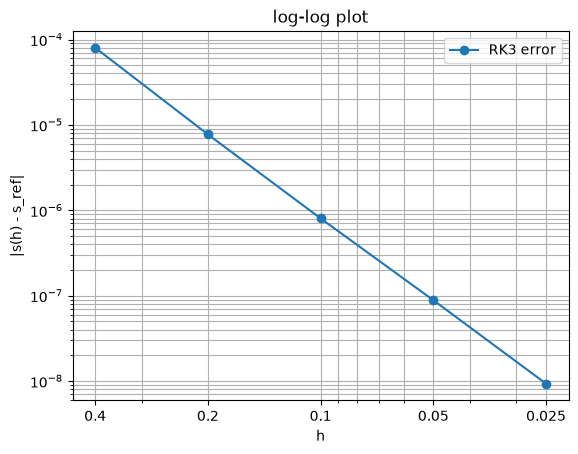

In [50]:
import matplotlib.pyplot as plt

plt.loglog(h_list, err, "o-", label="RK3 error")
plt.gca().invert_xaxis()
plt.xticks(h_list, [str(h) for h in h_list])
plt.gca().xaxis.set_minor_formatter(plt.NullFormatter())
plt.xlabel("h")
plt.ylabel("|s(h) - s_ref|")
plt.title("log-log plot")
plt.grid(True, which="both")
plt.legend()
plt.show()